Connection established successfully!


C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, con)


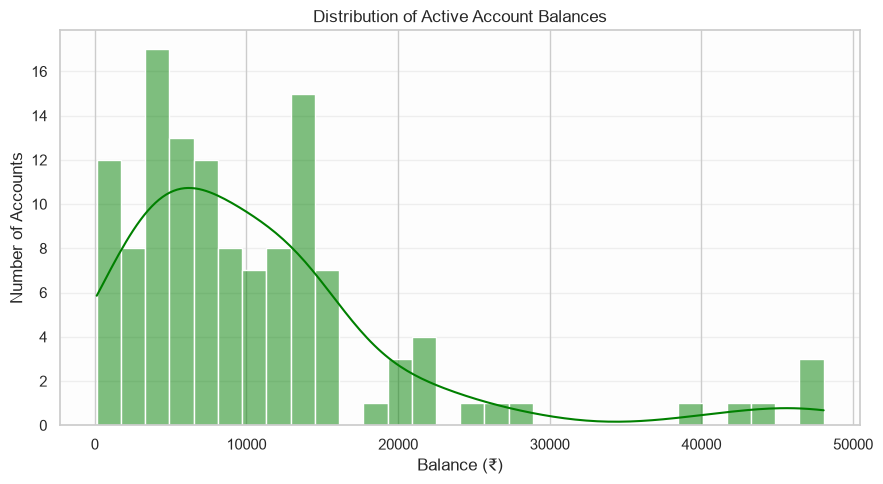

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:41: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, con)


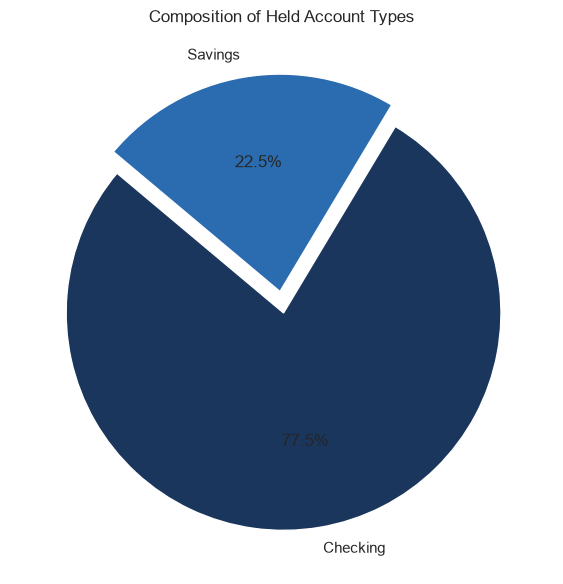

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, con)


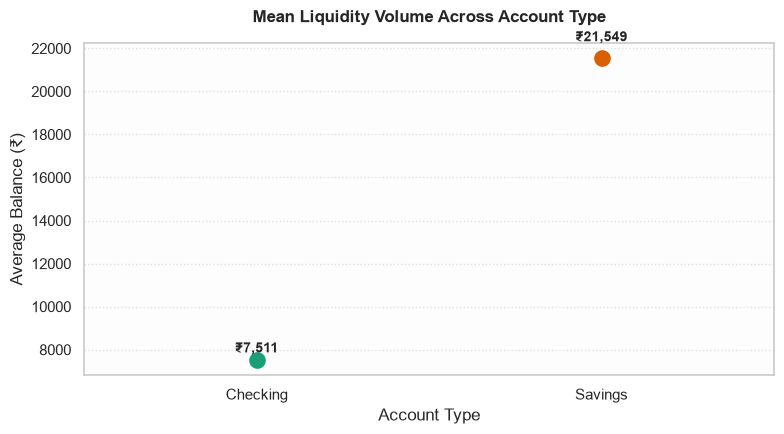

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:76: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df4 = pd.read_sql(query4, con)


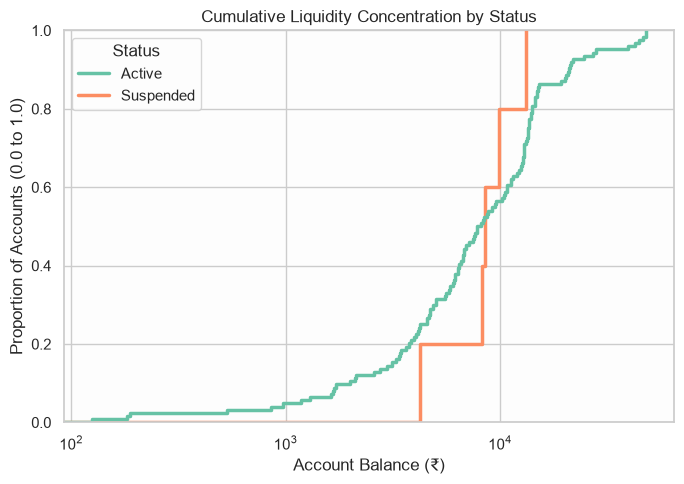

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:96: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, con)


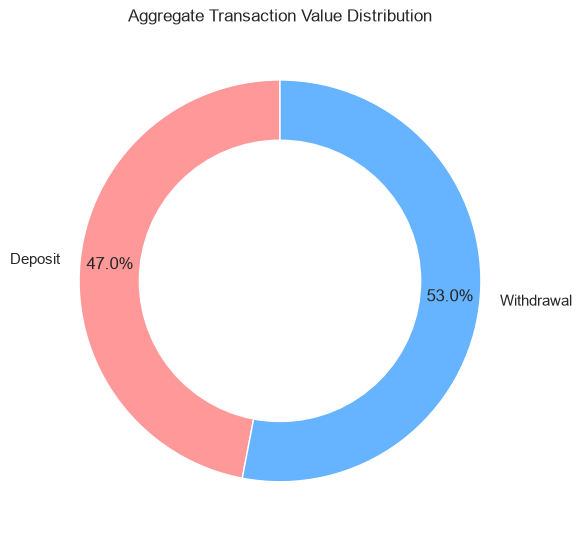

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:108: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df6 = pd.read_sql(query6, con)


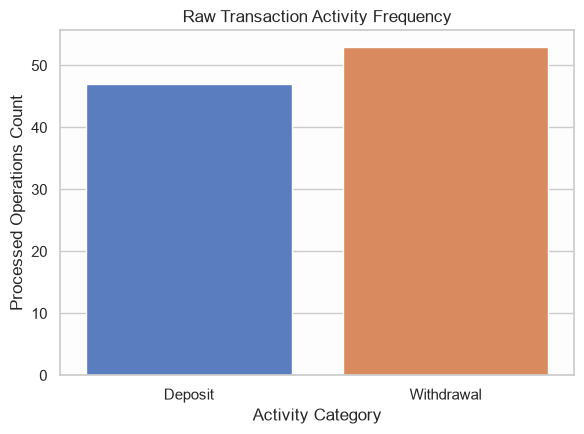

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:122: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df7 = pd.read_sql(query7, con)


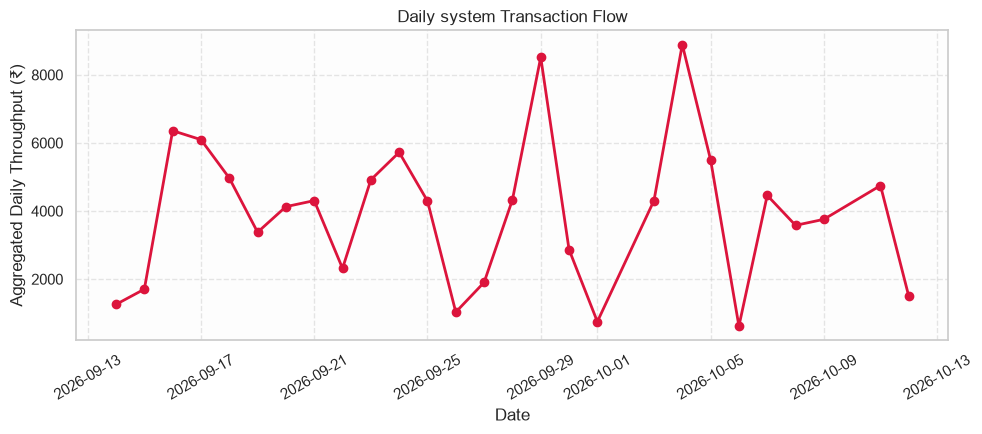

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:142: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df8 = pd.read_sql(query8, con)


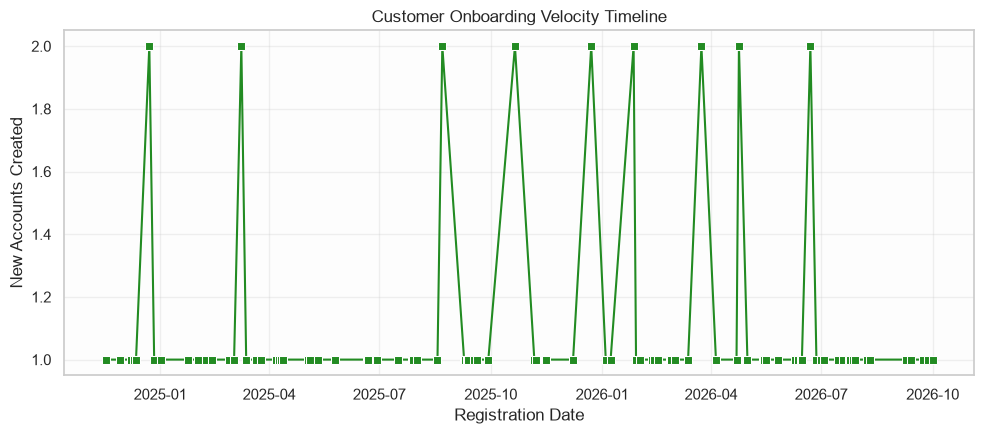

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:161: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df9 = pd.read_sql(query9, con)


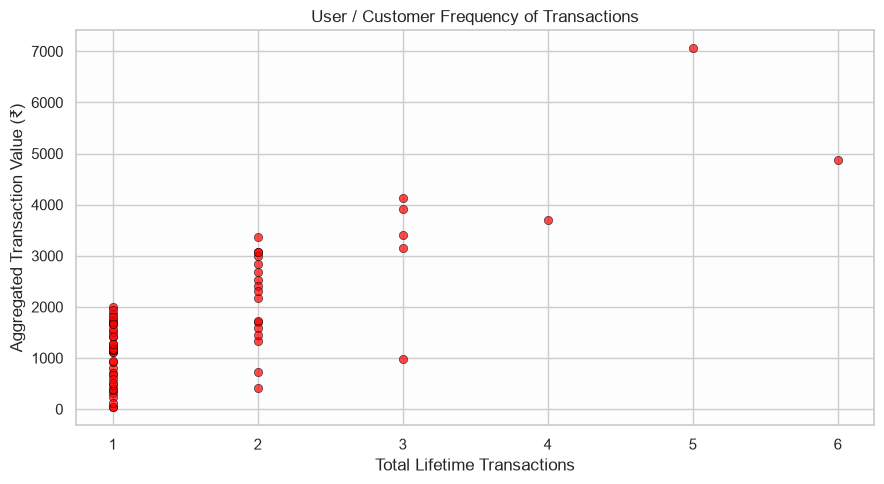

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2750033130.py:184: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df10 = pd.read_sql(query10, con)


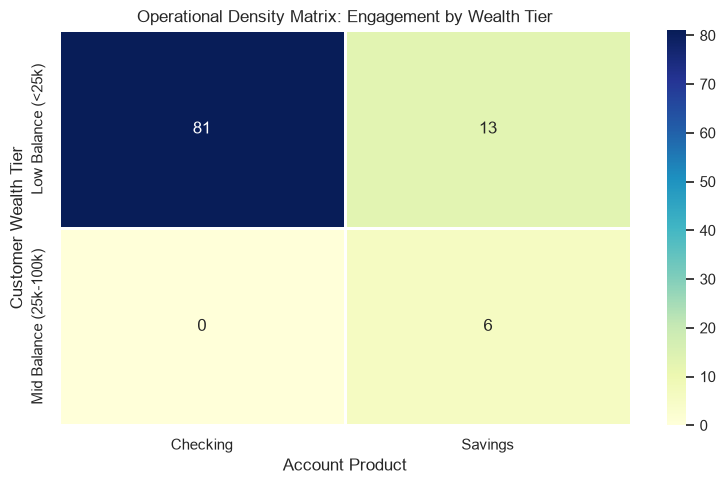

In [31]:
import mysql.connector 

con= mysql.connector.connect(
        host="localhost",
        user="root",
        password="root",
        database="banking"
    )
print("Connection established successfully!")

cursor = con.cursor()
query = "SELECT * FROM customers"
cursor.execute(query)
results = cursor.fetchall()
# for row in results:
#     print(row)


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.facecolor'] = '#ffffff'  
plt.rcParams['axes.facecolor'] = '#fdfdfd'  
#seaborn histplot

query1 = "SELECT Balance FROM Accounts WHERE Status = 'Active'"
df1 = pd.read_sql(query1, con)

plt.figure(figsize=(9, 5))
sns.histplot(df1['Balance'], kde=True, color='green', bins=30)
plt.title('Distribution of Active Account Balances')
plt.xlabel('Balance (₹)')
plt.ylabel('Number of Accounts')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

query2 = "SELECT AccountType, COUNT(*) as AccountCount FROM Accounts GROUP BY AccountType"
df2 = pd.read_sql(query2, con)
varcolors = ['#1a365d', '#2b6cb0', '#4299e1']
plt.figure(figsize=(6, 6))
plt.pie(df2['AccountCount'], labels=df2['AccountType'], autopct='%1.1f%%', 
        startangle=140, colors=varcolors, explode=[0.05] * len(df2))
plt.title('Composition of Held Account Types')
plt.tight_layout()
plt.show()

query3 = "SELECT AccountType, AVG(Balance) as AvgBalance FROM Accounts GROUP BY AccountType"
df3 = pd.read_sql(query3, con)

plt.figure(figsize=(8, 4.5))
sns.stripplot(
    x='AccountType', 
    y='AvgBalance', 
    data=df3, 
    hue='AccountType', 
    palette='Dark2', 
    size=12,            
    jitter=False,     
    legend=False
)
for index, row in df3.iterrows():
    plt.text(index, row['AvgBalance'] + (row['AvgBalance'] * 0.03), f"₹{row['AvgBalance']:,.0f}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Mean Liquidity Volume Across Account Type', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Account Type')
plt.ylabel('Average Balance (₹)')
plt.grid(visible=True, axis='y', linestyle=':', alpha=0.6, color='#cccccc')
plt.tight_layout()
plt.show()

query4 = "SELECT Status, Balance FROM Accounts"
df4 = pd.read_sql(query4, con)

plt.figure(figsize=(7, 5))
sns.ecdfplot(
    data=df4, 
    x='Balance', 
    hue='Status', 
    palette='Set2',
    linewidth=2.5
)

plt.title('Cumulative Liquidity Concentration by Status')
plt.xlabel('Account Balance (₹)')
plt.ylabel('Proportion of Accounts (0.0 to 1.0)')
plt.yscale('linear') 
plt.xscale('log')
plt.tight_layout()
plt.show()
 
query5 = "SELECT TransactionType, SUM(Amount) as TotalVolume FROM Transactions GROUP BY TransactionType"
df5 = pd.read_sql(query5, con)

plt.figure(figsize=(6, 6))
plt.pie(df5['TotalVolume'], labels=df5['TransactionType'], autopct='%1.1f%%',startangle=90, pctdistance=0.85, colors=['#ff9999','#66b3ff'])
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Aggregate Transaction Value Distribution')
plt.tight_layout()
plt.show()

query6 = "SELECT TransactionType FROM Transactions"
df6 = pd.read_sql(query6, con)

plt.figure(figsize=(6, 4.5))
sns.countplot(x='TransactionType', data=df6, hue='TransactionType', palette='muted', legend=False)
plt.title('Raw Transaction Activity Frequency')
plt.xlabel('Activity Category')
plt.ylabel('Processed Operations Count')
plt.tight_layout()
plt.show()

query7 = """SELECT DATE(TransactionDate) as TxDate, SUM(Amount) as DailyVolume 
    FROM Transactions 
    GROUP BY DATE(TransactionDate) 
    ORDER BY TxDate"""
df7 = pd.read_sql(query7, con)
df7['TxDate'] = pd.to_datetime(df7['TxDate'])

plt.figure(figsize=(10, 4.5))
plt.plot(df7['TxDate'], df7['DailyVolume'], color='crimson', marker='o', linewidth=2)
plt.title('Daily system Transaction Flow')
plt.xlabel('Date')
plt.ylabel('Aggregated Daily Throughput (₹)')
plt.xticks(rotation=30)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

query8 = """
    SELECT DATE(CreatedAt) as RegDate, COUNT(CustomerID) as NewUsers 
    FROM Customers 
    GROUP BY DATE(CreatedAt) 
    ORDER BY RegDate
"""

df8 = pd.read_sql(query8, con)
df8['RegDate'] = pd.to_datetime(df8['RegDate'])

plt.figure(figsize=(10, 4.5))
sns.lineplot(x='RegDate', y='NewUsers', data=df8, color='forestgreen', marker='s')
plt.title('Customer Onboarding Velocity Timeline')
plt.xlabel('Registration Date')
plt.ylabel('New Accounts Created')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


query9 = """
    SELECT a.CustomerID, COUNT(t.TransactionID) as TxCount, SUM(t.Amount) as TotalSpent
    FROM Accounts a
    JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY a.CustomerID
"""
df9 = pd.read_sql(query9, con)

plt.figure(figsize=(9, 5))
sns.scatterplot(x='TxCount', y='TotalSpent', data=df9, alpha=0.7, color='red', edgecolor='black')
plt.title('User / Customer Frequency of Transactions')
plt.xlabel('Total Lifetime Transactions')
plt.ylabel('Aggregated Transaction Value (₹)')
plt.tight_layout()
plt.show()

query10 = """
    SELECT 
        CASE 
            WHEN Balance < 25000 THEN 'Low Balance (<25k)'
            WHEN Balance BETWEEN 25000 AND 100000 THEN 'Mid Balance (25k-100k)'
            ELSE 'High Net Worth (>100k)'
        END as BalanceTier,
        AccountType,
        COUNT(t.TransactionID) as TotalTxCount
    FROM Accounts a
    LEFT JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY BalanceTier, AccountType
"""
df10 = pd.read_sql(query10, con)

# Reshape into cross-tabulated structure for the heatmap matrix
pivot_df = df10.pivot(index='BalanceTier', columns='AccountType', values='TotalTxCount').fillna(0)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_df, annot=True, fmt=".0f", cmap='YlGnBu', linewidths=1)
plt.title('Operational Density Matrix: Engagement by Wealth Tier')
plt.xlabel('Account Product')
plt.ylabel('Customer Wealth Tier')
plt.tight_layout()
plt.show()



C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2002626259.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_accounts = pd.read_sql_query("SELECT AccountType, Balance FROM Accounts;", con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2002626259.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_trans_counts = pd.read_sql_query("SELECT TransactionType, COUNT(*) as TotalCount FROM Transactions GROUP BY TransactionType;", con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\2002626259.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please c

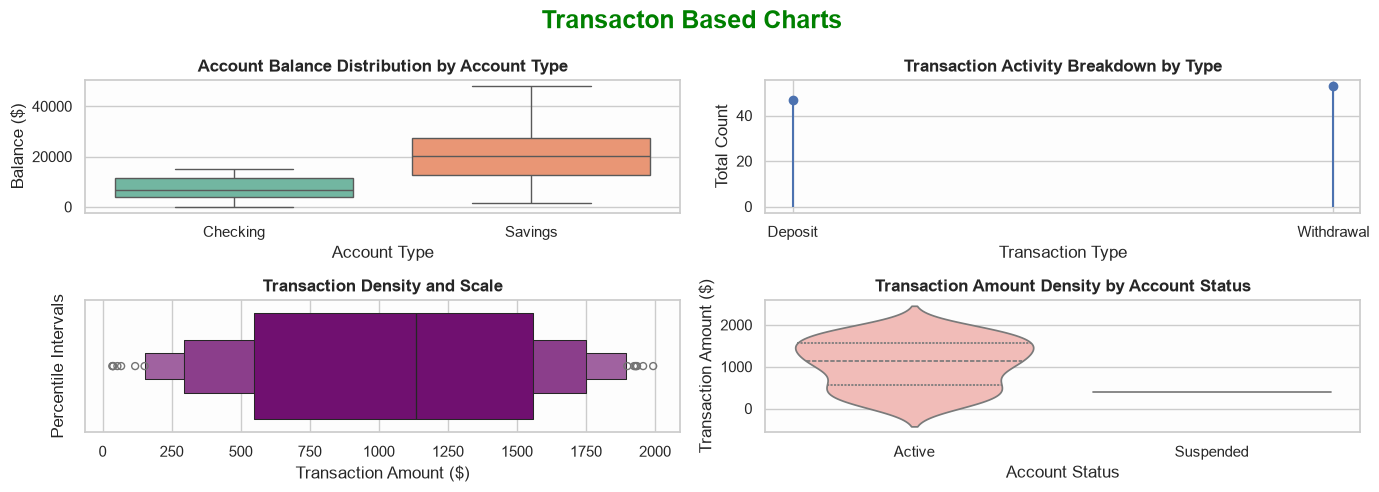

In [32]:
#Dashboard 1 - 4 charts
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector 
con = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="banking"
)

#Query for axes 1 

df_accounts = pd.read_sql_query("SELECT AccountType, Balance FROM Accounts;", con)

#Query for axes 2 
    
df_trans_counts = pd.read_sql_query("SELECT TransactionType, COUNT(*) as TotalCount FROM Transactions GROUP BY TransactionType;", con)

#Query for axes 3 
df_trans_amounts = pd.read_sql_query("SELECT Amount FROM Transactions;", con)

#Query for axes 4

query4 = "select a.Status, t.Amount from Transactions t join Accounts a on t.AccountID = a.AccountID";
df4 = pd.read_sql_query(query4, con)


fig, ax = plt.subplots(2, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")
fig.suptitle('Transacton Based Charts',fontsize=18,fontweight='bold',color='Green')

#chart1 Box Plot Chart
sns.boxplot(data=df_accounts, x='AccountType', y='Balance', palette='Set2', ax=ax[0, 0],hue='AccountType')
ax[0, 0].set_title('Account Balance Distribution by Account Type', fontsize=12, fontweight='bold')
ax[0, 0].set_xlabel('Account Type')
ax[0, 0].set_ylabel('Balance ($)')


#Chart2 - Lollipop or Stem chart

ax[0, 1].stem(df_trans_counts['TransactionType'], df_trans_counts['TotalCount'], 
              linefmt='b-', markerfmt='bo', basefmt=' ')

# Custom styling for clean visibility
ax[0, 1].set_title('Transaction Activity Breakdown by Type', fontsize=12, fontweight='bold')
ax[0, 1].set_xlabel('Transaction Type')
ax[0, 1].set_ylabel('Total Count')
#ax[0, 1].set_ylim(0, df_trans_counts['TotalCount'].max() * 1.15)

#Chart 3 - Histogram Chart
sns.boxenplot(data=df_trans_amounts, x='Amount', color='purple', ax=ax[1, 0])
ax[1, 0].set_title('Transaction Density and Scale', fontsize=12, fontweight='bold')
ax[1, 0].set_xlabel('Transaction Amount ($)')
ax[1, 0].set_ylabel('Percentile Intervals')

#chart4 - Violin Plot Chart (Tansaction Amount by status)
sns.violinplot(data=df4, x='Status', y='Amount', palette='Pastel1', inner='quartile', ax=ax[1, 1],legend=False,hue='Status')
ax[1, 1].set_title('Transaction Amount Density by Account Status', fontsize=12, fontweight='bold')
ax[1, 1].set_xlabel('Account Status')
ax[1, 1].set_ylabel('Transaction Amount ($)')
plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\3019408869.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\3019408869.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df6 = pd.read_sql(query6, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\3019408869.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df7 = pd.read_sql(query7, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11976\3019408869.py:53: UserWarning: pandas only su

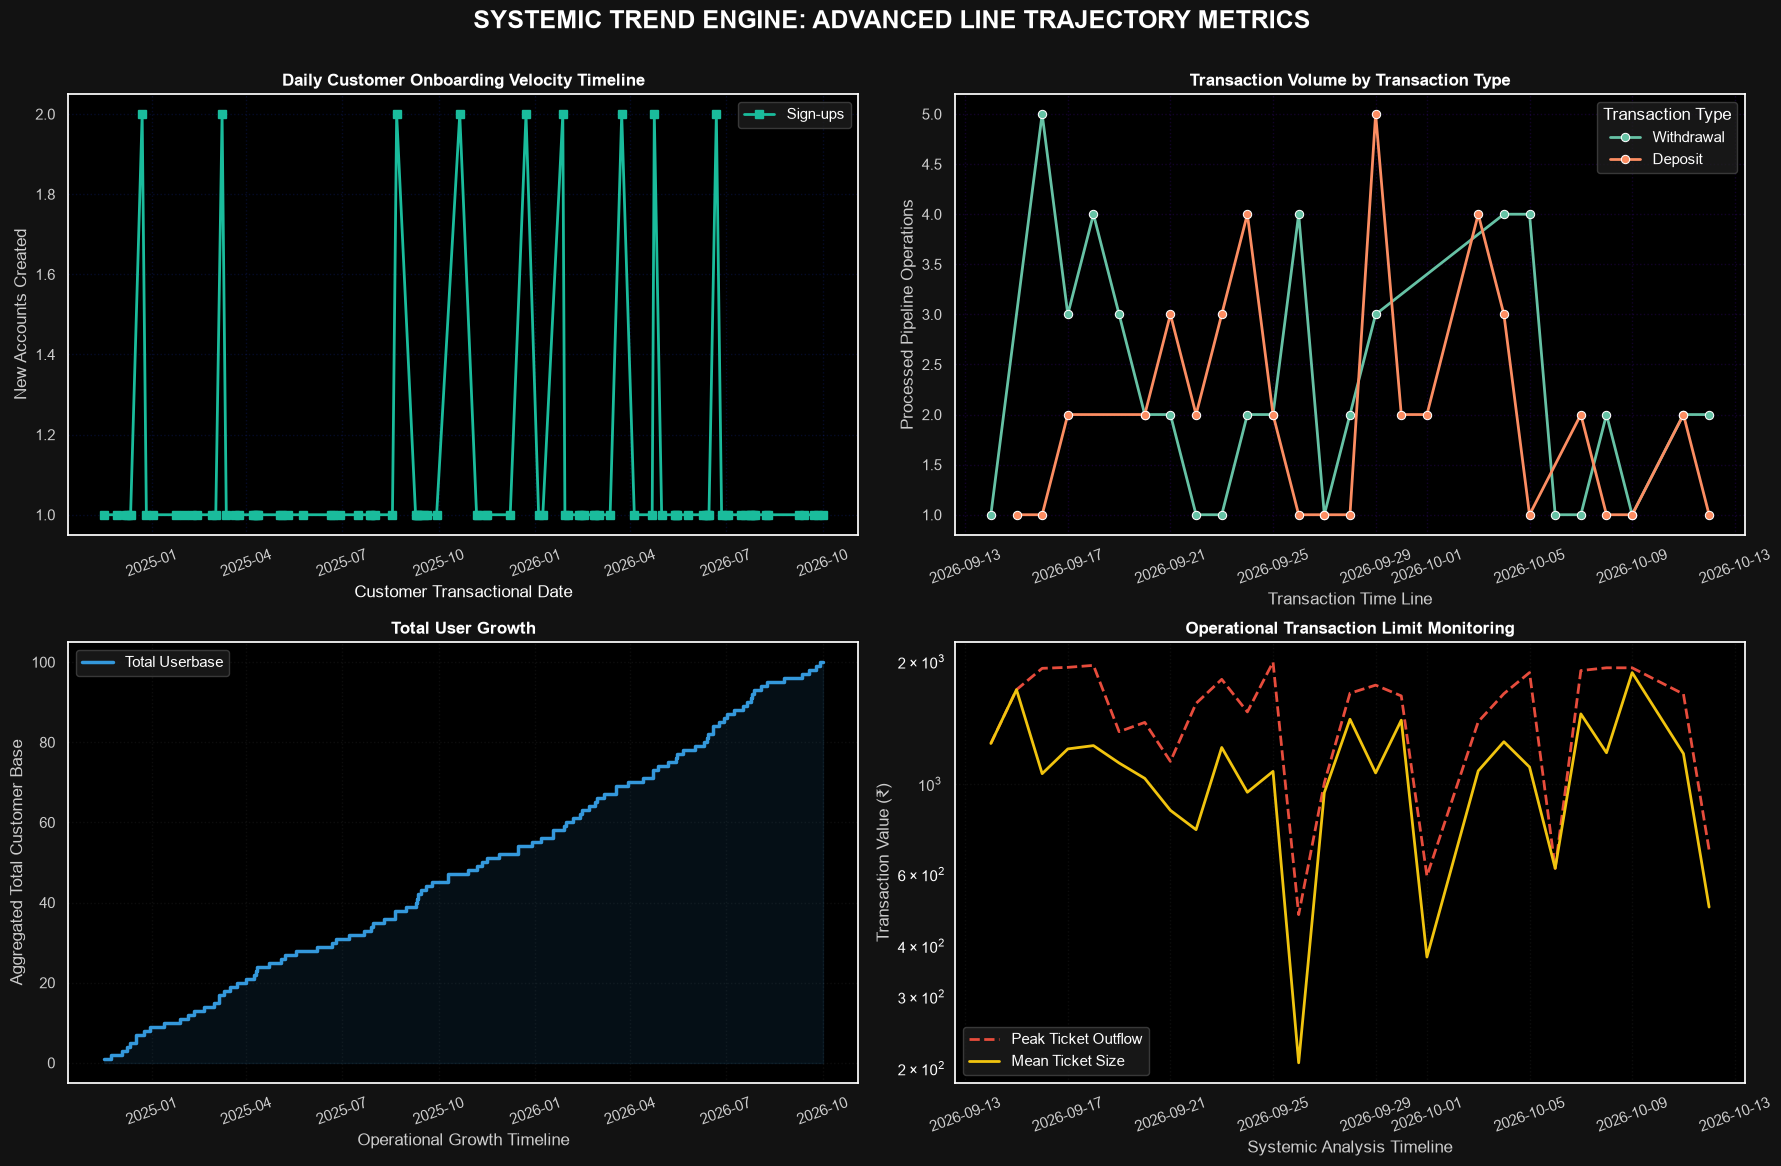

In [33]:
#Dashboard2 - 4 Charts


import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector 
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="banking"
)
import pandas as pd
plt.style.use('dark_background')
query5 = """
        SELECT DATE(CreatedAt) as RegDate, COUNT(CustomerID) as NewUsers 
        FROM Customers 
        GROUP BY DATE(CreatedAt) 
        ORDER BY RegDate
    """
df5 = pd.read_sql(query5, conn)
df5['RegDate'] = pd.to_datetime(df5['RegDate'])
    
# Chart 2 
query6 ="""
        SELECT DATE(TransactionDate) as TxDate, TransactionType, COUNT(*) as TxCount
        FROM Transactions
        GROUP BY DATE(TransactionDate), TransactionType
        ORDER BY TxDate
    """
df6 = pd.read_sql(query6, conn)
df6['TxDate'] = pd.to_datetime(df6['TxDate'])

# Chart 3 

query7 ="""
        SELECT DATE(CreatedAt) as RegDate, COUNT(*) as DailyCount
        FROM Customers
        GROUP BY DATE(CreatedAt)
        ORDER BY RegDate
    """
df7 = pd.read_sql(query7, conn)
df7['RegDate'] = pd.to_datetime(df7['RegDate'])
df7['RunningTotal'] = df7['DailyCount'].cumsum()
    
# Chart 4 
query8 ="""
        SELECT DATE(TransactionDate) as TxDate, MAX(Amount) as MaxAmount, AVG(Amount) as AvgAmount
        FROM Transactions
        GROUP BY DATE(TransactionDate)
        ORDER BY TxDate
    """
df8 = pd.read_sql(query8, conn)
df8['TxDate'] = pd.to_datetime(df8['TxDate'])
fig, axs = plt.subplots(2, 2, figsize=(18, 12), facecolor='#121212')
fig.suptitle('SYSTEMIC TREND ENGINE: ADVANCED LINE TRAJECTORY METRICS',fontsize=18, fontweight='bold', color='#ffffff', y=0.97)

#chart1 - Single Line Chart 
axs[0, 0].plot(df5['RegDate'], df5['NewUsers'], color='#1abc9c', marker='s', markersize=6, linewidth=2, label='Sign-ups')
axs[0, 0].set_title('Daily Customer Onboarding Velocity Timeline', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 0].set_xlabel('Customer Transactional Date')
axs[0, 0].set_ylabel('New Accounts Created', color='#cccccc')
axs[0, 0].grid(True, linestyle=':', alpha=0.2, color="#1C38C4")
axs[0, 0].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[0, 0].tick_params(axis='y', colors='#cccccc')
axs[0, 0].legend(facecolor='#1e1e1e', edgecolor='#444444')

#chart 2 - Transacation type multi series line chart

sns.lineplot(
    ax=axs[0, 1], 
    x='TxDate', 
    y='TxCount', 
    hue='TransactionType', 
    data=df6, 
    marker='o', 
    linewidth=2, 
    palette='Set2'
)
axs[0, 1].set_title('Transaction Volume by Transaction Type', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 1].set_xlabel('Transaction Time Line', color='#cccccc')
axs[0, 1].set_ylabel('Processed Pipeline Operations', color='#cccccc')
axs[0, 1].grid(True, linestyle=':', alpha=0.2, color="#5D0CCDD2")
axs[0, 1].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[0, 1].tick_params(axis='y', colors='#cccccc')
axs[0, 1].legend(title='Transaction Type', facecolor='#1e1e1e', edgecolor='#444444')

#Chart 3 - Step Line Chart - Total Asset or Total aggregate value of Customer

axs[1, 0].step(df7['RegDate'], df7['RunningTotal'], color='#3498db', where='mid', linewidth=2.5, label='Total Userbase')
axs[1, 0].fill_between(df7['RegDate'], df7['RunningTotal'], step="mid", color="#3498db", alpha=0.1)  # Optional subtle fill
axs[1, 0].set_title('Total User Growth', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 0].set_xlabel('Operational Growth Timeline', color='#cccccc')
axs[1, 0].set_ylabel('Aggregated Total Customer Base', color='#cccccc')
axs[1, 0].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[1, 0].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[1, 0].tick_params(axis='y', colors='#cccccc')
axs[1, 0].legend(loc='upper left', facecolor='#1e1e1e', edgecolor='#444444')

#Chart 4 - Date wise Transaction Max amount and Average Amount
axs[1, 1].plot(df8['TxDate'], df8['MaxAmount'], color='#e74c3c', linestyle='--', linewidth=2, label='Peak Ticket Outflow')
axs[1, 1].plot(df8['TxDate'], df8['AvgAmount'], color='#f1c40f', linestyle='-', linewidth=2, label='Mean Ticket Size')
axs[1, 1].set_title('Operational Transaction Limit Monitoring', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 1].set_xlabel('Systemic Analysis Timeline', color='#cccccc')
axs[1, 1].set_ylabel('Transaction Value (₹)', color='#cccccc')
axs[1, 1].set_yscale('log') 
axs[1, 1].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[1, 1].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[1, 1].tick_params(axis='y', colors='#cccccc')
axs[1, 1].legend(facecolor='#1e1e1e', edgecolor='#444444')

plt.tight_layout()
fig.subplots_adjust(top=0.90)

plt.show()
